# 512×512 NFFA-SEM box inpainting

This notebook evaluates a selected 512×512 SEM prior on a normalized NPY or preprocessed PNG. With `INPUT_IMAGE_PATH = None`, it chooses a deterministic held-out test NPY. It hides a square, reconstructs it, and compares against the clean image.

Set `INPUT_IMAGE_PATH` to an existing `.npy` or 512×512 `.png`. A PNG in `clean/centercrop_resized/resized/images` uses the paired center crop's percentile range, matching the training NPY exactly. For another PNG, set `PNG_REFERENCE_CROP_PATH` or the notebook will use its own percentiles and warn. Saved outputs may reflect an earlier selection; rerun all cells after changing the input.


In [ ]:
from pathlib import Path
import json
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

repo_root = Path.cwd().resolve()
if not (repo_root / "pnpflow").is_dir():
    candidate = repo_root.parent
    if (candidate / "pnpflow").is_dir():
        repo_root = candidate
    else:
        raise RuntimeError("Open this notebook from the PnP-Flow repository or its notebooks directory.")
os.chdir(repo_root)

DATASET_NAME = "sem_nffa_all10_centerresize_512"
# RUN_NAME = "20260922_150017_sem_nffa_all10_centerresize_512_ot_amp_4gpu_gb12"
RUN_NAME ='20260923_203800_sem_nffa_Patterned_surface_512_fp32_from_model20_gb8_130ep'
# CHECKPOINT_NAME = "model_70.pt"
CHECKPOINT_NAME = "model_final.pt"
checkpoint_path = repo_root / "model" / DATASET_NAME / "ot" / RUN_NAME / CHECKPOINT_NAME
processed_root = repo_root / "data" / DATASET_NAME
test_root = processed_root / "test"

TEST_SAMPLE_INDEX = 0
INPUT_IMAGE_PATH = None  # or an existing normalized .npy / 512x512 preprocessed .png
# Example PNG: /data2/marci/bselvaku/nffa_sem/clean/centercrop_resized/resized/images/Patterned_surface/L1_42f41ce892887c173c662419ff7e3885.png
PNG_REFERENCE_CROP_PATH = None  # optional center-crop PNG for exact normalization of another PNG
BOX_SIZE = 128
BOX_TOP = 192
BOX_LEFT = 192
STEPS_PNP = 100
NUM_SAMPLES = 5
NOISE_STD = 0.01
LR_PNP = 1.0
ALPHA = 1.0
USE_AMP = False

assert checkpoint_path.is_file(), f"Checkpoint not found: {checkpoint_path}"
test_files = sorted(test_root.rglob("*.npy"))
if not test_files:
    raise FileNotFoundError(f"No held-out test patches found under {test_root}")
if INPUT_IMAGE_PATH is None:
    if not 0 <= TEST_SAMPLE_INDEX < len(test_files):
        raise IndexError(f"TEST_SAMPLE_INDEX={TEST_SAMPLE_INDEX} but only {len(test_files)} test patches exist.")
    patch_path = test_files[TEST_SAMPLE_INDEX]
else:
    patch_path = Path(INPUT_IMAGE_PATH).expanduser()
    if not patch_path.is_absolute():
        patch_path = repo_root / patch_path
    patch_path = patch_path.resolve()
    if not patch_path.is_file():
        matches = list(processed_root.glob(f'*/{patch_path.parent.name}/{patch_path.name}'))
        hint = f' Found at {matches[0]}' if matches else ''
        raise FileNotFoundError(f'Input image not found: {patch_path}.{hint}')
    if patch_path.suffix.lower() not in {'.npy', '.png'}:
        raise ValueError(f'Expected a processed .npy or .png image, got {patch_path}')

input_class = patch_path.parent.name
split_matches = [split for split in ('train', 'val', 'test')
                 if (processed_root / split / input_class / f'{patch_path.stem}.npy').is_file()]
input_split = split_matches[0] if len(split_matches) == 1 else 'unknown'

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0)
if device.type == "cuda":
    torch.cuda.manual_seed_all(0)

print(f"Repository: {repo_root}")
print(f"Checkpoint: {checkpoint_path}")
print(f"Held-out test patches: {len(test_files)}")
print(f"Selected input: {patch_path}; class: {input_class}; split: {input_split}")
if input_split == 'train':
    print('Warning: this is a training image; masked PSNR is not held-out performance.')
print(f"Device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(device)}")


Repository: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow
Checkpoint: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/model/sem_nffa_all10_centerresize_512/ot/20260923_203800_sem_nffa_Patterned_surface_512_fp32_from_model20_gb8_130ep/model_70.pt
Held-out test patches: 2133
Selected patch: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/data/sem_nffa_all10_centerresize_512/test/Biological/L7_00ee245747d62518dcda5e5fa4540088.npy
Device: cuda:0
GPU: Tesla V100-SXM2-32GB


In [9]:
from pnpflow.utils import define_model

class ModelArgs:
    model = "ot"
    num_channels = 1
    dim_image = 512

model, _ = define_model(ModelArgs())
checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
state_dict = checkpoint.get('model_state_dict', checkpoint) if isinstance(checkpoint, dict) else checkpoint
model.load_state_dict(state_dict, strict=True)
model.to(device).eval()

image_format = patch_path.suffix.lower().lstrip('.')
normalization_reference = 'stored normalized NPY'
normalization_low_high = None
clean_root = processed_root.resolve().parents[2]
if image_format == 'npy':
    patch = np.load(patch_path, allow_pickle=False).astype(np.float32)
    if patch.ndim == 3 and patch.shape[0] == 1:
        patch = patch[0]
    if not np.isfinite(patch).all() or patch.min() < -1.001 or patch.max() > 1.001:
        raise ValueError(f'Expected a normalized finite NPY in [-1, 1], got {patch_path}')
else:
    with Image.open(patch_path) as handle:
        if handle.size != (512, 512):
            preview = clean_root / 'centercrop_resized' / 'resized' / 'images' / input_class / patch_path.name
            hint = f' Use the 512x512 preview at {preview}' if preview.is_file() else ''
            raise ValueError(f'Expected a 512x512 PNG, got {handle.size} from {patch_path}.{hint}')
        pixels = np.asarray(handle.convert('L'), dtype=np.uint8)
    preview_root = clean_root / 'centercrop_resized' / 'resized' / 'images'
    if PNG_REFERENCE_CROP_PATH is not None:
        reference_path = Path(PNG_REFERENCE_CROP_PATH).expanduser()
        if not reference_path.is_absolute():
            reference_path = repo_root / reference_path
        reference_path = reference_path.resolve()
        if not reference_path.is_file():
            raise FileNotFoundError(f'PNG normalization reference not found: {reference_path}')
    else:
        try:
            relative = patch_path.resolve().relative_to(preview_root.resolve())
            reference_path = clean_root / 'centercrop' / relative
        except ValueError:
            reference_path = None
    if reference_path is not None and reference_path.is_file():
        with Image.open(reference_path) as handle:
            reference = np.asarray(handle.convert('L'), dtype=np.uint8)
        normalization_reference = str(reference_path)
    else:
        reference = pixels
        normalization_reference = 'input PNG percentiles (no paired center crop found)'
        print('Warning: no paired center crop found; PNG normalization may differ from training.')
    low, high = np.percentile(reference.astype(np.float32), (1, 99))
    if not high > low:
        raise ValueError(f'PNG normalization has no usable intensity range: [{low}, {high}]')
    patch = 2.0 * np.clip((pixels.astype(np.float32) - low) / (high - low), 0, 1) - 1.0
    patch = patch.astype(np.float16).astype(np.float32)  # match stored training NPY quantization
    normalization_low_high = [float(low), float(high)]

if patch.shape != (512, 512) or not np.isfinite(patch).all():
    raise ValueError(f'Expected a finite 512 x 512 input, got {patch.shape} from {patch_path}')
clean = torch.from_numpy(patch)[None, None].to(device=device)

print(f"Loaded {image_format.upper()} input with shape {tuple(clean.shape)}")
print(f'Normalization source: {normalization_reference}')
print(f"Patch intensity range: {clean.min().item():.3f} to {clean.max().item():.3f}")


Loaded model_20.pt and test patch with shape (1, 1, 512, 512)
Patch intensity range: -1.000 to 1.000


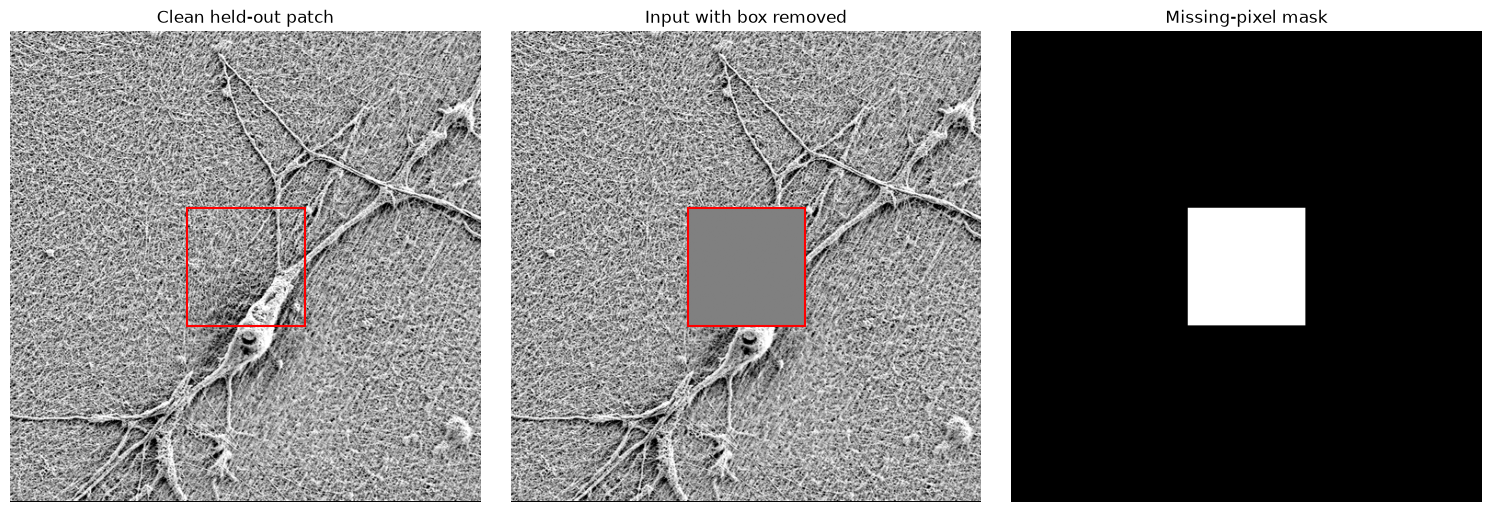

Box: y=192:320, x=192:320
Missing area: 6.25% of the patch


In [10]:
from matplotlib.patches import Rectangle
from pnpflow.degradations import FixedMaskInpainting

height, width = clean.shape[-2:]
if not (0 < BOX_SIZE < min(height, width)):
    raise ValueError(f"BOX_SIZE must be between 1 and {min(height, width) - 1}.")
if not (0 <= BOX_TOP <= height - BOX_SIZE and 0 <= BOX_LEFT <= width - BOX_SIZE):
    raise ValueError("The box coordinates fall outside the test patch.")

known_mask = torch.ones_like(clean)
known_mask[:, :, BOX_TOP:BOX_TOP + BOX_SIZE, BOX_LEFT:BOX_LEFT + BOX_SIZE] = 0
missing_mask = known_mask == 0
degradation = FixedMaskInpainting(known_mask)
observed = degradation.H(clean)

clean_np = clean[0, 0].detach().cpu().numpy()
observed_np = observed[0, 0].detach().cpu().numpy()
mask_np = missing_mask[0, 0].detach().cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
axes[0].imshow(clean_np, cmap="gray", vmin=-1, vmax=1)
axes[0].set_title("Clean input")
axes[1].imshow(observed_np, cmap="gray", vmin=-1, vmax=1)
axes[1].set_title("Input with box removed")
axes[2].imshow(mask_np, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Missing-pixel mask")
for ax in axes:
    ax.axis("off")
for ax in axes[:2]:
    ax.add_patch(Rectangle((BOX_LEFT, BOX_TOP), BOX_SIZE, BOX_SIZE, fill=False, edgecolor="red", linewidth=1.5))
plt.show()

print(f"Box: y={BOX_TOP}:{BOX_TOP + BOX_SIZE}, x={BOX_LEFT}:{BOX_LEFT + BOX_SIZE}")
print(f"Missing area: {100 * missing_mask.float().mean().item():.2f}% of the patch")


In [11]:
@torch.inference_mode()
def pnp_flow_box_inpaint(model, observed, degradation):
    known = degradation.H_adj(torch.ones_like(observed)).to(observed.device)
    x = degradation.H_adj(observed).clone()
    lr = NOISE_STD ** 2 * LR_PNP
    delta = 1.0 / STEPS_PNP
    amp_enabled = USE_AMP and observed.device.type == "cuda"

    for iteration in range(STEPS_PNP):
        t = torch.full((len(x),), delta * iteration, device=x.device, dtype=x.dtype)
        lr_t = lr * (1.0 - t).pow(ALPHA).view(-1, 1, 1, 1)
        z = x - lr_t * degradation.H_adj(degradation.H(x) - observed) / (NOISE_STD ** 2)

        x_new = torch.zeros_like(x)
        for _ in range(NUM_SAMPLES):
            t_view = t.view(-1, 1, 1, 1)
            z_tilde = t_view * z + (1.0 - t_view) * torch.randn_like(z)
            if amp_enabled:
                with torch.autocast(device_type="cuda", dtype=torch.float16):
                    velocity = model(z_tilde, t)
            else:
                velocity = model(z_tilde, t)
            x_new += (z_tilde + (1.0 - t_view) * velocity).float()

        x_new /= NUM_SAMPLES
        x = known * observed + (1.0 - known) * x_new
        if (iteration + 1) % 5 == 0 or iteration == 0:
            print(f"PnP iteration {iteration + 1}/{STEPS_PNP}")

    return x

start_time = time.perf_counter()
reconstruction = pnp_flow_box_inpaint(model, observed, degradation)
if device.type == "cuda":
    torch.cuda.synchronize()
elapsed_seconds = time.perf_counter() - start_time

reconstruction_np = reconstruction[0, 0].detach().cpu().numpy()
missing_np = missing_mask[0, 0].detach().cpu().numpy()
observed_np_mask = ~missing_np
error = reconstruction_np - clean_np
masked_mse = float(np.mean(error[missing_np] ** 2))
zero_fill_mse = float(np.mean(clean_np[missing_np] ** 2))
data_consistency_error = float(np.max(np.abs(reconstruction_np[observed_np_mask] - observed_np[observed_np_mask])))
masked_psnr = float(10.0 * np.log10(4.0 / max(masked_mse, 1e-12)))
zero_fill_psnr = float(10.0 * np.log10(4.0 / max(zero_fill_mse, 1e-12)))

print(f"Masked-region PSNR: {masked_psnr:.2f} dB (zero-fill baseline: {zero_fill_psnr:.2f} dB)")
print(f"Max observed-pixel change: {data_consistency_error:.3g}")
print(f"Inference time: {elapsed_seconds:.1f} seconds")


PnP iteration 1/100
PnP iteration 5/100
PnP iteration 10/100
PnP iteration 15/100
PnP iteration 20/100
PnP iteration 25/100
PnP iteration 30/100
PnP iteration 35/100
PnP iteration 40/100
PnP iteration 45/100
PnP iteration 50/100
PnP iteration 55/100
PnP iteration 60/100
PnP iteration 65/100
PnP iteration 70/100
PnP iteration 75/100
PnP iteration 80/100
PnP iteration 85/100
PnP iteration 90/100
PnP iteration 95/100
PnP iteration 100/100
Masked-region PSNR: 13.14 dB (zero-fill baseline: 12.67 dB)
Max observed-pixel change: 0
Inference time: 98.1 seconds


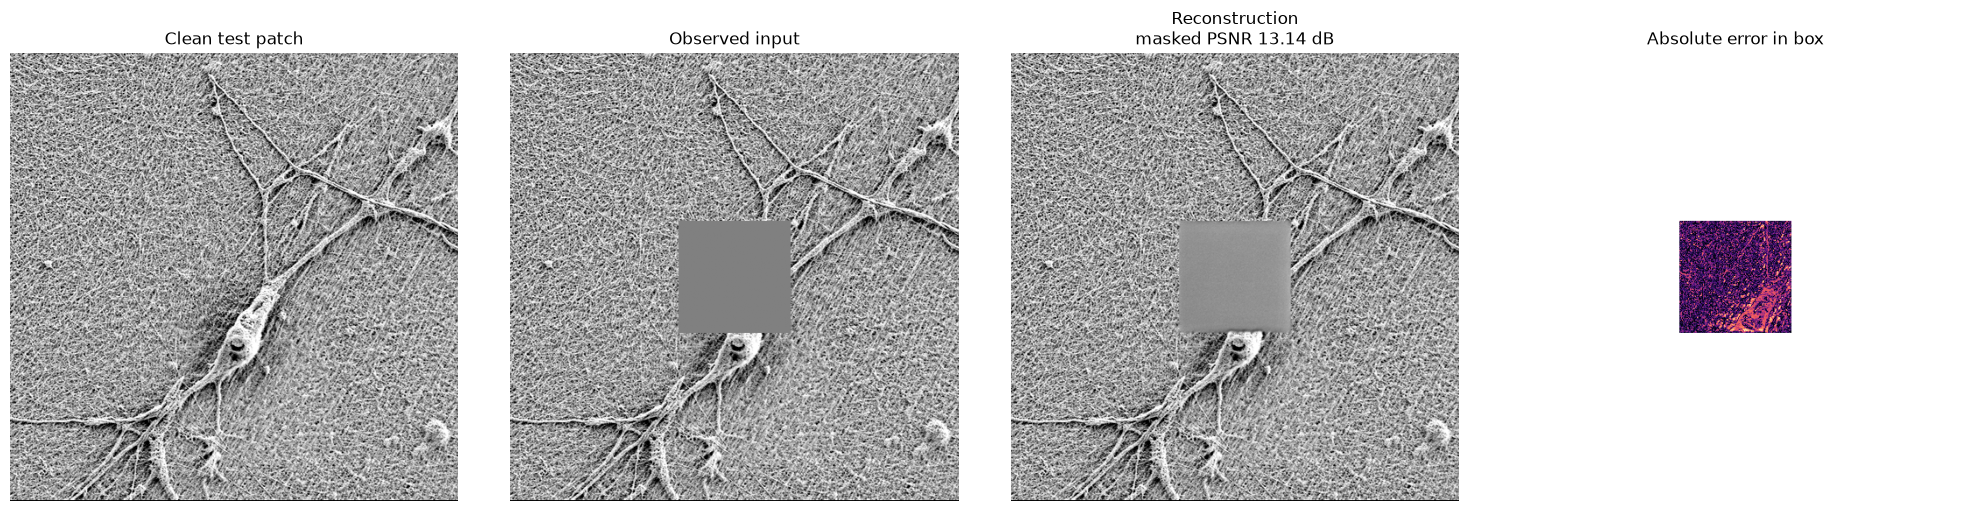

Saved figure: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/notebooks/outputs/20260923_203800_sem_nffa_Patterned_surface_512_fp32_from_model20_gb8_130ep/box_inpainting_test0_Biological_L7_00ee245747d62518dcda5e5fa4540088.png
Saved reconstruction: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/notebooks/outputs/20260923_203800_sem_nffa_Patterned_surface_512_fp32_from_model20_gb8_130ep/box_inpainting_test0_Biological_L7_00ee245747d62518dcda5e5fa4540088_reconstruction.npy
Saved metrics: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/notebooks/outputs/20260923_203800_sem_nffa_Patterned_surface_512_fp32_from_model20_gb8_130ep/box_inpainting_test0_Biological_L7_00ee245747d62518dcda5e5fa4540088_metrics.json


In [12]:
error_display = np.where(missing_np, np.abs(error), np.nan)
fig, axes = plt.subplots(1, 4, figsize=(20, 5), constrained_layout=True)
panels = [
    (clean_np, "Clean input", "gray"),
    (observed_np, "Observed input", "gray"),
    (reconstruction_np, f"Reconstruction\nmasked PSNR {masked_psnr:.2f} dB", "gray"),
    (error_display, "Absolute error in box", "magma"),
]
for ax, (image, title, cmap) in zip(axes, panels):
    if cmap == "magma":
        ax.imshow(image, cmap=cmap, vmin=0, vmax=max(float(np.nanmax(image)), 1e-6))
    else:
        ax.imshow(image, cmap=cmap, vmin=-1, vmax=1)
    ax.set_title(title)
    ax.axis("off")
plt.show()

output_dir = repo_root / "notebooks" / "outputs" / RUN_NAME
output_dir.mkdir(parents=True, exist_ok=True)
output_stem = f"box_inpainting_{input_split}_{input_class}_{patch_path.stem}_mask{BOX_SIZE}"
figure_path = output_dir / f"{output_stem}.png"
reconstruction_path = output_dir / f"{output_stem}_reconstruction.npy"
metrics_path = output_dir / f"{output_stem}_metrics.json"

fig.savefig(figure_path, dpi=160, bbox_inches="tight")
np.save(reconstruction_path, reconstruction_np.astype(np.float32))
metrics = {
    "checkpoint": str(checkpoint_path),
    "input_image": str(patch_path),
    "input_split": input_split,
    "input_class": input_class,
    "input_format": image_format,
    "normalization_reference": normalization_reference,
    "normalization_low_high": normalization_low_high,
    "box": {"top": BOX_TOP, "left": BOX_LEFT, "size": BOX_SIZE},
    "steps": STEPS_PNP,
    "num_samples": NUM_SAMPLES,
    "masked_psnr_db": masked_psnr,
    "zero_fill_baseline_masked_psnr_db": zero_fill_psnr,
    "max_observed_pixel_change": data_consistency_error,
    "inference_seconds": elapsed_seconds,
}
metrics_path.write_text(json.dumps(metrics, indent=2) + "\n")
print(f"Saved figure: {figure_path}")
print(f"Saved reconstruction: {reconstruction_path}")
print(f"Saved metrics: {metrics_path}")
